## Imports y funciones base

In [8]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import subprocess
import joblib
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit
import csv


sys.path.insert(0, str(Path.cwd().parent / "src"))
from train_model import (cargar_conjuntos, baseline_persistencia, baseline_media_movil, evaluar,
                         registrar_experimento, optimizar, entrenar_y_evaluar)

SEED = 42

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
conjuntos, features = cargar_conjuntos()
train, val = conjuntos["train"], conjuntos["val"]   # test queda en conjuntos["test"]: se usa una sola vez, al final
X_train, y_train = train[features], train["target"]
X_val, y_val = val[features], val["target"]
print(f"{len(features)} features | X_train {X_train.shape} | X_val {X_val.shape}")

train: 846 días | 2020-07-04 -> 2022-10-27
val: 182 días | 2022-10-28 -> 2023-04-27
test: 182 días | 2023-04-28 -> 2023-10-26
27 features | X_train (846, 27) | X_val (182, 27)


## Creación de los baselines

In [10]:
frio = "Consolidado EE | Frio (Kw)"
coincide = (val["target"].iloc[:-1].to_numpy() == val[frio].iloc[1:].to_numpy()).mean()
print(f"target[D] == Frío[D+1] en el {coincide:.1%} de los días de validación")

target[D] == Frío[D+1] en el 100.0% de los días de validación


In [11]:
predicciones_base = {
    "persistencia": baseline_persistencia(val),
    "media_movil_7": baseline_media_movil(val, previo=train),
}

resultados_base = {}
for nombre, pred in predicciones_base.items():
    metricas = evaluar(y_val, pred)
    registrar_experimento(nombre, "validacion", metricas, semilla=SEED)
    resultados_base[nombre] = metricas

pd.DataFrame(resultados_base).T.round({"mae": 0, "rmse": 0, "r2": 3})

,mae,rmse,r2
persistencia,2700.0,3360.0,0.246
media_movil_7,2455.0,3299.0,0.273


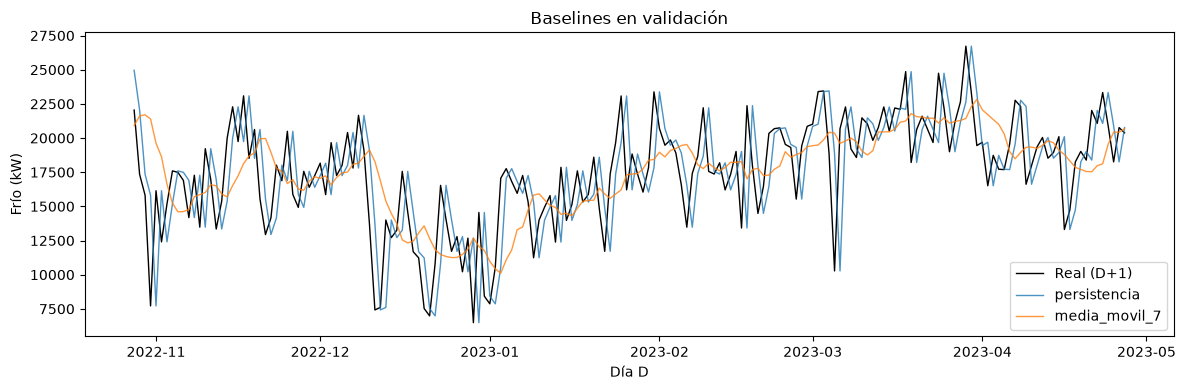

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(val["DIA"], y_val, label="Real (D+1)", color="black", linewidth=1)
for nombre, pred in predicciones_base.items():
    ax.plot(val["DIA"], pred, label=nombre, linewidth=1, alpha=0.8)
ax.set_xlabel("Día D")
ax.set_ylabel("Frío (kW)")
ax.set_title("Baselines en validación")
ax.legend()
plt.tight_layout()
plt.show()

## Experimentos

In [ ]:
def espacio_ridge(trial):
    return {"alpha": trial.suggest_float("alpha", 1e-3, 1e5, log=True)}


def espacio_lasso(trial):
    return {"alpha": trial.suggest_float("alpha", 1, 1e4, log=True)}


def espacio_random_forest(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 40),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 40),
        "max_features": trial.suggest_float("max_features", 0.1, 1.0),
        "max_samples": trial.suggest_float("max_samples", 0.5, 1.0),
    }


def espacio_xgboost(trial):
    return {
        "objective": trial.suggest_categorical("objective", ["reg:squarederror", "reg:absoluteerror"]),
        "n_estimators": trial.suggest_int("n_estimators", 100, 2000, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "colsample_bylevel": trial.suggest_float("colsample_bylevel", 0.5, 1.0),
        "colsample_bynode": trial.suggest_float("colsample_bynode", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 1e4, log=True),
    }


def espacio_lightgbm(trial):
    return {
        "objective": trial.suggest_categorical("objective", ["regression", "regression_l1"]),
        "n_estimators": trial.suggest_int("n_estimators", 100, 2000, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 4, 128, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "feature_fraction_bynode": trial.suggest_float("feature_fraction_bynode", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 1e4, log=True),
        "extra_trees": trial.suggest_categorical("extra_trees", [False, True]),
    }

In [ ]:
# for nombre, espacio in [("ridge", espacio_ridge), ("lasso", espacio_lasso),
#                         ("random_forest", espacio_random_forest), ("xgboost", espacio_xgboost),
#                         ("lightgbm", espacio_lightgbm)]:
#     optimizar(nombre, espacio, X_train, y_train, n_trials=3, semilla=SEED, registrar=False)

  0%|          | 0/3 [00:00<?, ?it/s]

ridge: 3 completos, 0 podados | MAE CV 3,005 ± 435 kW


  0%|          | 0/3 [00:00<?, ?it/s]

lasso: 3 completos, 0 podados | MAE CV 3,016 ± 407 kW


  0%|          | 0/3 [00:00<?, ?it/s]

random_forest: 3 completos, 0 podados | MAE CV 3,129 ± 256 kW


  0%|          | 0/3 [00:00<?, ?it/s]

xgboost: 3 completos, 0 podados | MAE CV 3,146 ± 390 kW


  0%|          | 0/3 [00:00<?, ?it/s]

lightgbm: 3 completos, 0 podados | MAE CV 3,230 ± 559 kW


In [15]:
estudio_ridge = optimizar("ridge", espacio_ridge, X_train, y_train, n_trials=200, semilla=SEED)

  0%|          | 0/200 [00:00<?, ?it/s]

ridge: 17 completos, 183 podados | MAE CV 3,004 ± 440 kW


In [16]:
estudio_lasso = optimizar("lasso", espacio_lasso, X_train, y_train, n_trials=200, semilla=SEED)

  0%|          | 0/200 [00:00<?, ?it/s]

lasso: 52 completos, 148 podados | MAE CV 2,998 ± 391 kW


In [17]:
estudio_rf = optimizar("random_forest", espacio_random_forest, X_train, y_train,
                        n_trials=500, timeout=int(1.5 * 3600), semilla=SEED)

  0%|          | 0/500 [00:00<?, ?it/s]

random_forest: 71 completos, 429 podados | MAE CV 3,107 ± 276 kW


In [21]:
estudio_xgb = optimizar("xgboost", espacio_xgboost, X_train, y_train,
                        n_trials=50, timeout=2 * 3600, semilla=SEED)

  0%|          | 0/50 [00:00<?, ?it/s]

xgboost: 24 completos, 26 podados | MAE CV 3,042 ± 259 kW


In [22]:
estudio_lgbm = optimizar("lightgbm", espacio_lightgbm, X_train, y_train,
                         n_trials=50, timeout=2 * 3600, semilla=SEED)

  0%|          | 0/50 [00:00<?, ?it/s]

lightgbm: 40 completos, 10 podados | MAE CV 3,056 ± 284 kW


In [23]:
estudios = {"ridge": estudio_ridge, "lasso": estudio_lasso, "random_forest": estudio_rf,
            "xgboost": estudio_xgb, "lightgbm": estudio_lgbm}
pd.DataFrame({n: {"mae_cv": e.best_value,
                  "desvio_folds": e.best_trial.user_attrs["mae_desvio_folds"],
                  "trials": len(e.trials),
                  "podados": sum(t.state.name == "PRUNED" for t in e.trials)}
              for n, e in estudios.items()}).T.round(0)

,mae_cv,desvio_folds,trials,podados
ridge,3004.0,440.0,200.0,183.0
lasso,2998.0,391.0,200.0,148.0
random_forest,3107.0,276.0,500.0,429.0
xgboost,3042.0,259.0,50.0,26.0
lightgbm,3056.0,284.0,50.0,10.0


## Logs de Experimentos

El script train_model es el que los trabaja y guarda los logs en results.

In [24]:
ruta_log = Path.cwd().parent / "results" / "experiment_logs.csv"
with open(ruta_log, encoding="utf-8", newline="") as f:
    filas = list(csv.reader(f))

rotos = sum(len(fila) == 1 for fila in filas)
if rotos:
    filas = [next(csv.reader([fila[0]])) if len(fila) == 1 else fila for fila in filas]
    with open(ruta_log, "w", encoding="utf-8", newline="") as f:
        csv.writer(f, lineterminator="\n").writerows(filas)

log = pd.read_csv(ruta_log, parse_dates=["timestamp"])
log["hiperparametros"] = log["hiperparametros"].apply(json.loads)
log["features"] = log["features"].apply(lambda s: json.loads(s) if isinstance(s, str) else None)

In [25]:
# Cada fila cv_train es un experimento (el mejor trial de una búsqueda de Optuna)
cv = log[log["conjunto"] == "cv_train"].reset_index(drop=True)
cv.index = pd.RangeIndex(1, len(cv) + 1, name="experimento")

tabla_experimentos = pd.DataFrame({
    "modelo": cv["modelo"], "fin": cv["timestamp"], "n_features": cv["n_features"].astype(int),
    "mae_cv": cv["mae"], "desvio_folds": cv["mae_desvio_folds"],
    "trials": cv["trials_completos"], "podados": cv["trials_podados"],
    "mejores_hiperparametros": cv["hiperparametros"].apply(
        lambda h: {k: round(v, 4) if isinstance(v, float) else v for k, v in h.items()}),
})
with pd.option_context("display.max_colwidth", None):
    display(tabla_experimentos.round({"mae_cv": 0, "desvio_folds": 0}))

,modelo,fin,n_features,mae_cv,desvio_folds,trials,podados,mejores_hiperparametros
experimento,,,,,,,,
1,ridge,2026-11-15 20:03:37,27,3004.0,440.0,17.0,183.0,{'alpha': 0.0029}
2,lasso,2026-11-15 20:03:41,27,2998.0,391.0,52.0,148.0,{'alpha': 62.7232}
3,random_forest,2026-11-15 20:14:21,27,3107.0,276.0,71.0,429.0,"{'n_estimators': 550, 'max_depth': 14, 'min_samples_split': 3, 'min_samples_leaf': 6, 'max_features': 0.3171, 'max_samples': 0.5735}"
4,xgboost,2026-11-15 20:15:20,27,3056.0,275.0,13.0,5.0,"{'objective': 'reg:squarederror', 'n_estimators': 600, 'learning_rate': 0.0104, 'max_depth': 10, 'min_child_weight': 6.1174, 'subsample': 0.8318, 'colsample_bytree': 0.8909, 'colsample_bylevel': 0.7457, 'colsample_bynode': 0.8772, 'reg_lambda': 40.0483, 'reg_alpha': 93.8385}"
5,xgboost,2026-11-15 20:15:37,27,3146.0,390.0,3.0,0.0,"{'objective': 'reg:absoluteerror', 'n_estimators': 450, 'learning_rate': 0.0411, 'max_depth': 7, 'min_child_weight': 1.1993, 'subsample': 0.8038, 'colsample_bytree': 0.4194, 'colsample_bylevel': 0.5325, 'colsample_bynode': 0.9744, 'reg_lambda': 67.3225, 'reg_alpha': 455.8075}"
6,xgboost,2026-11-15 20:17:38,27,3042.0,259.0,24.0,26.0,"{'objective': 'reg:squarederror', 'n_estimators': 650, 'learning_rate': 0.0109, 'max_depth': 10, 'min_child_weight': 12.8741, 'subsample': 0.8829, 'colsample_bytree': 0.7722, 'colsample_bylevel': 0.8961, 'colsample_bynode': 0.5847, 'reg_lambda': 37.8693, 'reg_alpha': 13.4372}"
7,lightgbm,2026-11-15 20:19:41,27,3056.0,284.0,40.0,10.0,"{'objective': 'regression_l1', 'n_estimators': 1400, 'learning_rate': 0.0088, 'num_leaves': 12, 'max_depth': 7, 'min_child_samples': 15, 'subsample': 0.5627, 'colsample_bytree': 0.9869, 'feature_fraction_bynode': 0.6687, 'reg_lambda': 28.6723, 'reg_alpha': 13.4723, 'extra_trees': False}"


Para los arboles, me quedo con el 8 y el 12, el random forest y el xgboost que so nlos dos últimos que corrí con la combinación correcta de features.

Para LASSO/Ridge, me quedo con los últimos (6 y 7). 

## Comparo sobre los mismos folds

Indico cuales de los logs quiero usar para comparar:

In [ ]:
# Modelos del log (por número de experimento de tabla_experimentos)
experimentos_a_comparar = {"rf": 3, "xgb": 6, "lgbm": 7, "lasso": 2, 'ridge':1}

Y los miro primero por valor de los logs:

In [81]:
comparacion = {nombre: tabla_experimentos.loc[num, ["mae_cv", "desvio_folds"]]
               for nombre, num in experimentos_a_comparar.items()}

predicciones_base_train = {"persistencia": baseline_persistencia(train),
                           "media_movil_7": baseline_media_movil(train)}   # solo miran hacia atrás: se calculan sobre todo train
for nombre, pred in predicciones_base_train.items():
    maes = [evaluar(y_train.iloc[idx], pred.iloc[idx])["mae"]
            for _, idx in TimeSeriesSplit(n_splits=4, test_size=91).split(X_train)]
    comparacion[nombre] = pd.Series({"mae_cv": np.mean(maes), "desvio_folds": np.std(maes)})

pd.DataFrame(comparacion).T.astype(float).sort_values("mae_cv").round(0)

,mae_cv,desvio_folds
lasso_corrida2,2897.0,294.0
rf_corrida2,3060.0,202.0
xgb_corrida2,3064.0,278.0
lgbm_corrida2,3077.0,263.0
persistencia,3506.0,437.0
media_movil_7,3641.0,515.0


Y por validación (elijo los modelos):

In [75]:
experimentos_a_comparar_val = {"rf_corrida2": 8, "xgb_corrida2": 12, "lgbm_corrida2": 11, "lasso_corrida2": 7}

In [ ]:
comparacion_val = {nombre: m["mae"] for nombre, m in resultados_base.items()}
predicciones_val, config_val = {}, {}

for nombre, num in experimentos_a_comparar_val.items():
    mejor = cv.loc[num]
    if mejor["features"] != features:
        distintas = set(mejor["features"]) ^ set(features)
        print(f"Aviso: {nombre} (experimento {num}) se buscó con otras features "
              f"({len(mejor['features'])} contra {len(features)} actuales, {len(distintas)} distintas): "
              f"se entrena con las actuales")
    _, pred, metricas = entrenar_y_evaluar(mejor["modelo"], mejor["hiperparametros"], train, val, features,
                                           "validacion", semilla=SEED, registrar=False)
    comparacion_val[nombre] = metricas["mae"]
    predicciones_val[nombre] = pred
    config_val[nombre] = {"modelo": mejor["modelo"], "hiperparametros": mejor["hiperparametros"]}

tabla_comparacion_val = pd.DataFrame({"mae_val": comparacion_val})
mejor_base = tabla_comparacion_val.loc[list(resultados_base), "mae_val"].min()
tabla_comparacion_val["mejora_vs_mejor_baseline_%"] = (1 - tabla_comparacion_val["mae_val"] / mejor_base) * 100
tabla_comparacion_val.sort_values("mae_val").round({"mae_val": 0, "mejora_vs_mejor_baseline_%": 1})

,mae_val,mejora_vs_mejor_baseline_%
rf_corrida2,2215.0,9.8
xgb_corrida2,2272.0,7.5
lgbm_corrida2,2318.0,5.6
media_movil_7,2455.0,0.0
persistencia,2700.0,-9.9
lasso_corrida2,2923.0,-19.0


In [86]:
elegido = tabla_comparacion_val.drop(index=list(resultados_base))["mae_val"].idxmin()
modelo_tipo = config_val[elegido]["modelo"]
params_elegido = config_val[elegido]["hiperparametros"]
print(f"Modelo elegido: {elegido} ({modelo_tipo}) | MAE validación {tabla_comparacion_val.loc[elegido, 'mae_val']:,.0f} "
      f"| mejora sobre el mejor baseline: {tabla_comparacion_val.loc[elegido, 'mejora_vs_mejor_baseline_%']:.1f} %")

Modelo elegido: rf_corrida2 (random_forest) | MAE validación 2,215 | mejora sobre el mejor baseline: 9.8 %


## Graficos

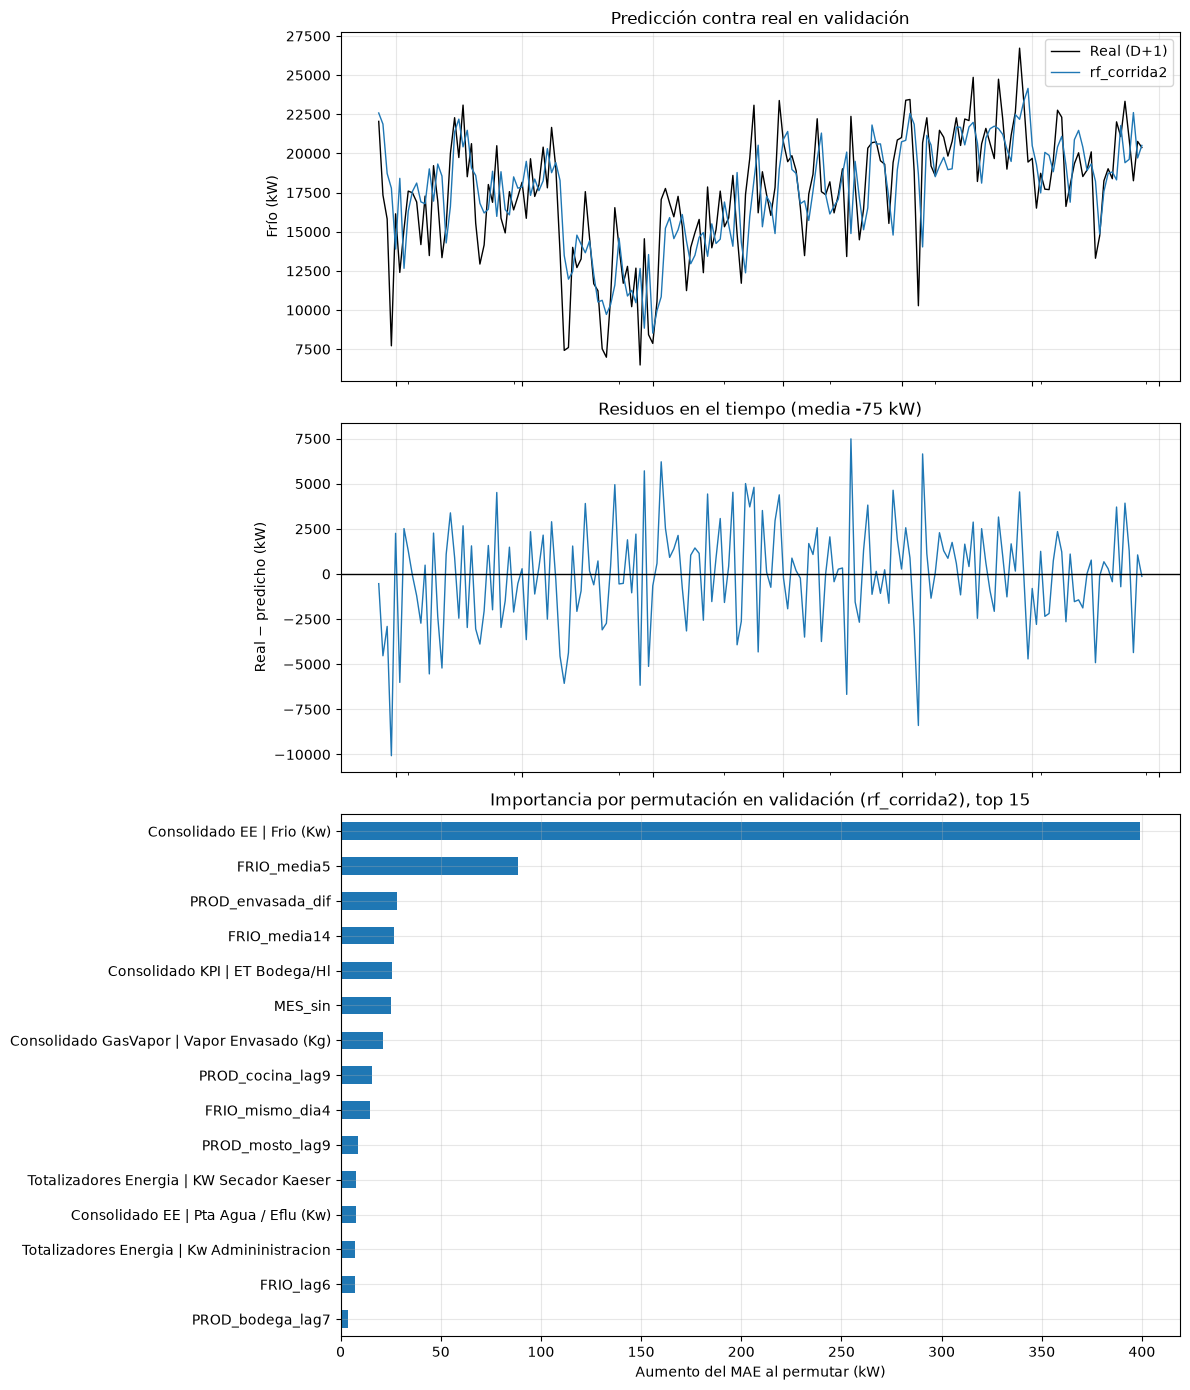

In [92]:
pred = predicciones_val[elegido]
residuo = y_val - pred

modelo_elegido, _, _ = entrenar_y_evaluar(modelo_tipo, params_elegido, train, val, features,
                                          "validacion", semilla=SEED, registrar=False)
imp = permutation_importance(modelo_elegido, X_val, y_val, scoring="neg_mean_absolute_error",
                             n_repeats=10, random_state=SEED)
importancia = pd.Series(imp.importances_mean, index=features).sort_values()

fig, axes = plt.subplots(3, 1, figsize=(12, 14), gridspec_kw={"height_ratios": [1, 1, 1.5]})

axes[0].plot(val["DIA"], y_val, label="Real (D+1)", color="black", linewidth=1)
axes[0].plot(val["DIA"], pred, label=elegido, linewidth=1)
axes[0].set_ylabel("Frío (kW)")
axes[0].set_title("Predicción contra real en validación")
axes[0].legend()

axes[1].plot(val["DIA"], residuo, linewidth=1)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].sharex(axes[0])
axes[1].set_xlabel("Día D")
axes[1].set_ylabel("Real − predicho (kW)")
axes[1].set_title(f"Residuos en el tiempo (media {residuo.mean():,.0f} kW)")

importancia.tail(15).plot.barh(ax=axes[2])
axes[2].set_xlabel("Aumento del MAE al permutar (kW)")
axes[2].set_title(f"Importancia por permutación en validación ({elegido}), top 15")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Modelo final
Uso el versionado semantico para el modelo final, y mi vara para cambiar las versiones va a ser:
- Major: cambian las features de entrada o el dataset; el modelo se va a romper
- Minor: cambia el modelo u otros hiperparámetros.
- PATCH: reentrenamiento con la misma configuración, cuando corrigo un valor o una columna puntual, etc.

In [98]:
tipo_cambio = "minor"     # "major" / "minor" / "patch": solo se usa si la configuración cambió respecto de la última versión

In [99]:
params = params_elegido

ruta_registro = Path.cwd().parent / "models" / "model_registry.json"
texto = ruta_registro.read_text(encoding="utf-8").strip() if ruta_registro.is_file() else ""
registro = json.loads(texto) if texto else {"latest": None, "versiones": {}}

if registro["latest"] is None:
    version = "1.0.0"
else:
    ultima = registro["versiones"][registro["latest"]]
    if ultima["modelo"] == modelo_tipo and ultima["hiperparametros"] == params and ultima["features"] == features:
        version = registro["latest"]      # misma configuración: un Run All no crea una versión nueva
    else:
        mayor, menor, parche = (int(p) for p in registro["latest"].split("."))
        version = {"major": f"{mayor + 1}.0.0", "minor": f"{mayor}.{menor + 1}.0",
                   "patch": f"{mayor}.{menor}.{parche + 1}"}[tipo_cambio]
print(f"{elegido} -> versión {version} (última registrada: {registro['latest']})")

rf_corrida2 -> versión 1.0.0 (última registrada: 1.0.0)


In [100]:
# train_model.py: mide en validación (entrenado con train), reentrena con train + validación,
# guarda models/modelo_v<version>.pkl y actualiza models/model_registry.json
corrida = subprocess.run([sys.executable, str(Path.cwd().parent / "src" / "train_model.py"),
                          version, modelo_tipo, json.dumps(params)],
                         capture_output=True, text=True, encoding="utf-8")
print(corrida.stdout)
if corrida.returncode != 0:
    raise RuntimeError(corrida.stderr)

info = json.loads(ruta_registro.read_text(encoding="utf-8"))["versiones"][version]
print(f"MAE validación: script {info['metricas_validacion']['mae']:,.0f} | notebook {tabla_comparacion_val.loc[elegido, 'mae_val']:,.0f}")
{k: info[k] for k in ["path", "modelo", "hiperparametros", "metricas_validacion", "commit", "cambios_sin_commitear"]}

Modelo elegido: random_forest | {'n_estimators': 150, 'max_depth': 11, 'min_samples_split': 10, 'min_samples_leaf': 7, 'max_features': 0.5708487839378247, 'max_samples': 0.7098373760011485}
train: 849 días | 2020-07-01 -> 2022-10-27
val: 182 días | 2022-10-28 -> 2023-04-27
test: 182 días | 2023-04-28 -> 2023-10-26
Validación: MAE 2,215 | RMSE 2,860 | R² 0.454
Aviso: la versión 1.0.0 ya estaba en el registro y se reemplaza.
Aviso: hay cambios sin commitear; el hash del registro no reproduce exactamente este modelo.
Guardados modelo_v1.0.0.pkl y model_registry.json (versión 1.0.0)

MAE validación: script 2,215 | notebook 2,215


{'path': 'models/modelo_v1.0.0.pkl',
 'modelo': 'random_forest',
 'hiperparametros': {'n_estimators': 150,
  'max_depth': 11,
  'min_samples_split': 10,
  'min_samples_leaf': 7,
  'max_features': 0.5708487839378247,
  'max_samples': 0.7098373760011485},
 'metricas_validacion': {'mae': 2214.7992391326875,
  'rmse': 2859.788654222807,
  'r2': 0.4539158916764485},
 'commit': 'c5d4d6a',
 'cambios_sin_commitear': True}

## Evaluación final en test

Lo hago cargando la ultima versión del modelo, para no romper nada y no mandarmela.

In [96]:
test = conjuntos["test"]
registro = json.loads((Path.cwd().parent / "models" / "model_registry.json").read_text(encoding="utf-8"))
version = registro["latest"]
info = registro["versiones"][version]
modelo_final = joblib.load(Path.cwd().parent / info["path"])

pred_test = {
    f"{info['modelo']} v{version}": pd.Series(modelo_final.predict(test[info["features"]]), index=test.index),
    "persistencia": baseline_persistencia(test),
    "media_movil_7": baseline_media_movil(test, previo=pd.concat([train, val])),
}
resultados_test = {}
for nombre, p in pred_test.items():
    resultados_test[nombre] = evaluar(test["target"], p)
    registrar_experimento(nombre, "test", resultados_test[nombre], semilla=SEED,
                          hiperparametros=info["hiperparametros"] if nombre.endswith(version) else None)

tabla_test = pd.DataFrame(resultados_test).T
tabla_test["mejora_vs_mejor_baseline_%"] = (1 - tabla_test["mae"] / tabla_test.loc[["persistencia", "media_movil_7"], "mae"].min()) * 100
tabla_test.round({"mae": 0, "rmse": 0, "r2": 3, "mejora_vs_mejor_baseline_%": 1})

,mae,rmse,r2,mejora_vs_mejor_baseline_%
random_forest v1.0.0,2757.0,3614.0,0.600,10.1
persistencia,3434.0,4510.0,0.377,-11.9
media_movil_7,3068.0,3975.0,0.516,0.0


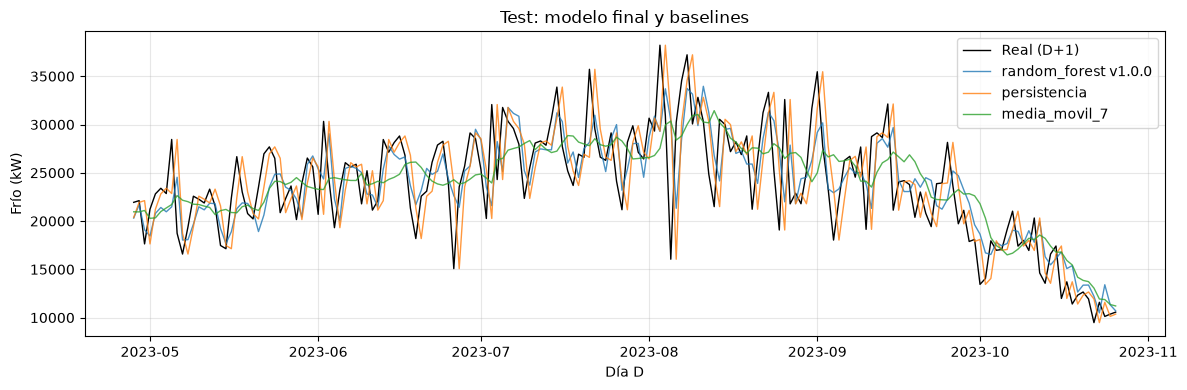

In [97]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test["DIA"], test["target"], label="Real (D+1)", color="black", linewidth=1)
for nombre, p in pred_test.items():
    ax.plot(test["DIA"], p, label=nombre, linewidth=1, alpha=0.8)
ax.set_xlabel("Día D"); ax.set_ylabel("Frío (kW)"); ax.set_title("Test: modelo final y baselines")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()